# 01 · Preprocessing — Kim et al. 2018 (TNBC, Nanogrid)

Load malignant cells → per-sample threshold → HVG → PCA → Harmony(`sample`) integration sweep → UMAP → island removal → cell-cycle & signature identity checks → **Gate 1** (mixing + continuity).

Malignant cells carry the publication `cell_type=='Malignant'` label. Expression is **TPM** (log1p'd by the loader). The `sample` field is patient×timepoint and is the Harmony batch key.

In [1]:
import os, sys, glob, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import scipy.sparse as sp
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# paths — notebook runs in place, two levels deeper than Puram (Category partition)
name = os.path.basename(os.getcwd())                    # Kim2018_Breast
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Breast
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Kim2018_Breast | category: Breast


## Load malignant cells

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
MAL_RAW = adata.shape[0]
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of TPM, passthrough)' % adata.X.max())
adata

Loading ../../../../../../data/unzip/CCCA/Data_Kim2018_Breast
Done.
full atlas: (2472, 12472)
malignant: (2375, 12472) | samples: 16
expression: X max 2.85 (log1p of TPM, passthrough)


AnnData object with n_obs × n_vars = 2375 × 12472
    obs: 'sample', 'patient', 'cell_type', 'cell_subtype', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'time_point', 'treatment', 'histology', 'age', 'tnm_stage', 'grade', 'celltype'
    uns: 'log1p'

## Per-sample threshold — gap-finder

Sort per-sample malignant counts and look for a **dominant multiplicative cliff**. If none exists (smooth distribution) fall to the floor ≥100. The largest ratio gap (21→6, ~3.5) barely exceeds its runner-up (~3.0), so there is **no dominant cliff** → floor ≥100 — which coincides with the real 52→100 inflection, dropping only sparsely-sampled (≤52-cell) samples.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios)); srt = np.sort(ratios)[::-1]; top, second = srt[0], srt[1]
FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*FLOOR)
print('sorted per-sample counts:', dict(zip(n.index, n.values.astype(int))))
print('gap ratios:', [f'{int(vals[i])}->{int(vals[i+1])}:{ratios[i]:.2f}' for i in range(len(ratios))])
print(f'argmax gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {top:.2f}); top/second = {top/second:.2f}; dominant cliff = {dominant}')
thresh = int(np.sqrt(vals[gap]*vals[gap+1])) if dominant else FLOOR
print(('dominant cliff -> geom-mean threshold = ' if dominant else 'no dominant cliff -> floor >= ') + str(thresh))
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
CELLS_AFTER_THRESH = adata.shape[0]
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n[n>=thresh].min())}) -> {CELLS_AFTER_THRESH} cells')

sorted per-sample counts: {'P14_pre': np.int64(474), 'P14_post': np.int64(373), 'P9_pre': np.int64(360), 'P15_pre': np.int64(246), 'P15_mid': np.int64(214), 'P6_pre': np.int64(191), 'P12_mid': np.int64(164), 'P1_pre': np.int64(141), 'P6_post': np.int64(100), 'P9_mid': np.int64(52), 'P11_post': np.int64(28), 'P1_post': np.int64(21), 'P2_post': np.int64(6), 'P12_pre': np.int64(3), 'P2_pre': np.int64(1), 'P11_pre': np.int64(1)}
gap ratios: ['474->373:1.27', '373->360:1.04', '360->246:1.46', '246->214:1.15', '214->191:1.12', '191->164:1.16', '164->141:1.16', '141->100:1.41', '100->52:1.92', '52->28:1.86', '28->21:1.33', '21->6:3.50', '6->3:2.00', '3->1:3.00', '1->1:1.00']
argmax gap 21->6 (ratio 3.50); top/second = 1.17; dominant cliff = False
no dominant cliff -> floor >= 100
kept 9/16 samples (min per-sample = 100) -> 2263 cells


## Gene filter, overdispersion, PCA

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
N_HVG = int(adata.var.highly_variable.sum())
print('overdispersed genes:', N_HVG)
sc.pp.pca(adata, n_comps=50)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 536 over-dispersed features (0:00:00) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 536


## Cell-cycle scoring

The publication `cell_cycle_phase`/`g1s_score`/`g2m_score` fields are empty for malignant cells, so phase is scored here (Tirosh S/G2M lists) — needed to test whether any manifold sub-region is a proliferation compartment before Gate 1.

In [6]:
s_genes = ('MCM5 PCNA TYMS FEN1 MCM2 MCM4 RRM1 UNG GINS2 MCM6 CDCA7 DTL PRIM1 UHRF1 HELLS RFC2 RPA2 '
    'NASP RAD51AP1 GMNN WDR76 SLBP CCNE2 UBR7 POLD3 MSH2 ATAD2 RAD51 RRM2 CDC45 CDC6 EXO1 TIPIN DSCC1 '
    'BLM CASP8AP2 USP1 CLSPN POLA1 CHAF1B BRIP1 E2F8').split()
g2m_genes = ('HMGB2 CDK1 NUSAP1 UBE2C BIRC5 TPX2 TOP2A NDC80 CKS2 NUF2 CKS1B MKI67 TMPO CENPF TACC3 '
    'FAM64A SMC4 CCNB2 CKAP2L CKAP2 AURKB BUB1 KIF11 ANP32E TUBB4B GTSE1 KIF20B HJURP CDCA3 HN1 CDC20 TTK '
    'CDC25C KIF2C RANGAP1 NCAPD2 DLGAP5 CDCA2 CDCA8 ECT2 KIF23 HMMR AURKA PSRC1 ANLN LBR CKAP5 CENPE CTCF '
    'NEK2 G2E3 GAS2L3 CBX5 CENPA').split()
sc.tl.score_genes_cell_cycle(adata, s_genes=[g for g in s_genes if g in adata.var_names],
                             g2m_genes=[g for g in g2m_genes if g in adata.var_names])
adata.obs['cycling'] = adata.obs['phase'].isin(['S','G2M'])
print('phase:', adata.obs['phase'].value_counts().to_dict())
print('overall cycling fraction: %.3f' % adata.obs['cycling'].mean())

phase: {'G2M': 1029, 'G1': 705, 'S': 529}
overall cycling fraction: 0.688


## Harmony integration sweep on `sample`

TNBC carries a strong patient-specific batch effect (pre-Harmony same-sample neighbour fraction ≈ 0.99). Sweep θ ∈ {2, 5, 10}: mixing improves and the two low-θ density lobes merge. **θ=10** yields a single continuous, well-mixed mass — chosen for the strong batch effect without collapsing structure (same rationale as the Olalekan HGSOC reference). The sweep panel below is a diagnostic, not a deliverable.

In [7]:
def _same_sample_frac(rep):
    idx = NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))
base = _same_sample_frac(adata.obsm['X_pca'][:,:20]); sweep = {}
umaps = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:20])
    sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
    sc.tl.umap(adata, spread=1.3, random_state=SEED)
    umaps[th] = adata.obsm['X_umap'].copy()
print('same-sample neighbour fraction | pre-Harmony %.3f' % base, '| sweep', {k: round(v,3) for k,v in sweep.items()})

2026-08-05 01:19:30,715 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-05 01:19:31,116 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-05 01:19:31,127 - harmonypy - INFO - Iteration 1 of 30
2026-08-05 01:19:31,563 - harmonypy - INFO - Iteration 2 of 30
2026-08-05 01:19:31,940 - harmonypy - INFO - Iteration 3 of 30
2026-08-05 01:19:32,298 - harmonypy - INFO - Iteration 4 of 30
2026-08-05 01:19:32,653 - harmonypy - INFO - Iteration 5 of 30
2026-08-05 01:19:33,083 - harmonypy - INFO - Iteration 6 of 30
2026-08-05 01:19:33,319 - harmonypy - INFO - Iteration 7 of 30
2026-08-05 01:19:33,532 - harmonypy - INFO - Converged after 7 iterations
2026-08-05 01:19:44,349 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-05 01:19:44,661 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-05 01:19:44,669 - harmonypy - INFO - Iteration 1 of 30
2026-08-05 01:19:45,085 - harmonypy - INFO - Iteration 2 of 

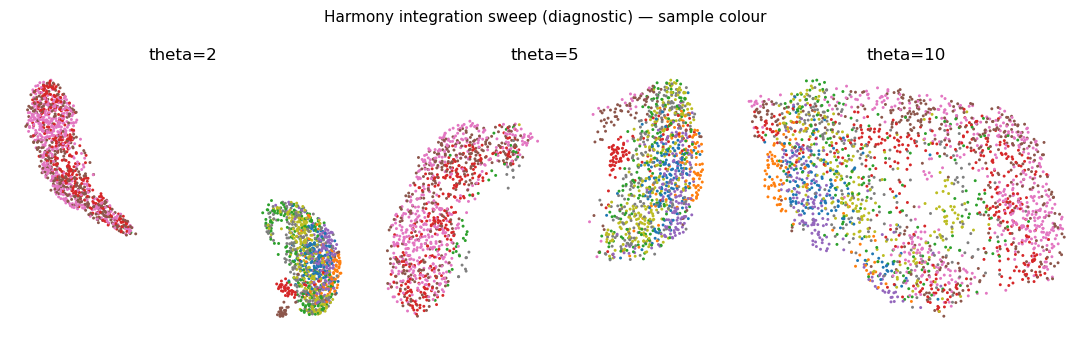

In [8]:
# diagnostic: sample colouring across the theta sweep (two low-theta lobes -> one mass at theta=10)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for j, th in enumerate([2, 5, 10]):
    adata.obsm['X_umap'] = umaps[th]
    sc.pl.umap(adata, color='sample', size=18, ax=axes[j], show=False, frameon=False,
               title=f'theta={th}', legend_loc=None)
fig.suptitle('Harmony integration sweep (diagnostic) — sample colour', size=11)
fig.tight_layout(); plt.show()

In [9]:
theta = 10
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('selected theta =', theta, '| n_pcs=20, spread=1.3')

selected theta = 10 | n_pcs=20, spread=1.3


## Island removal — keep the largest connected component

Radius graph at 6× median nearest-neighbour distance; keep the largest component. A conservative strip of only disconnected specks.

In [10]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
N_REMOVED = int((lab!=main).sum())
print('removed', N_REMOVED, 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
CELLS_AFTER_ISLAND = adata.shape[0]
print('after island removal:', CELLS_AFTER_ISLAND, 'cells')

removed 0 cells in 0 detached islands
after island removal: 2263 cells


## Sub-region identity — signatures + cell cycle (biology before Gate 1)

Score the three embryonic modules with the **union** control pool, graph-smooth for a spatial read, and confirm no separate cycling lobe splits off (proliferating cells intermix). The smoothed module correlations already reveal the axis: Gast↔pSom anti-correlate (organized cross-repression) and Crest tracks the Gast pole.

In [11]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{l}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = S[:,j]
print('raw module means:', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
print('smoothed spatial correlations:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.2f}')
print('cycling fraction: %.3f (elevated but intermixed across the manifold; no separate proliferation lobe to scope out)' % adata.obs['cycling'].mean())

Gast: 63/81 genes present
pSom: 66/98 genes present
Crest: 71/104 genes present
raw module means: {'Gast': -0.0094, 'pSom': 0.0403, 'Crest': -0.0848}
smoothed spatial correlations:
  Gast_sm vs pSom_sm: r = -0.84
  Crest_sm vs Gast_sm: r = +0.90
  Crest_sm vs pSom_sm: r = -0.84
cycling fraction: 0.688 (elevated but intermixed across the manifold; no separate proliferation lobe to scope out)


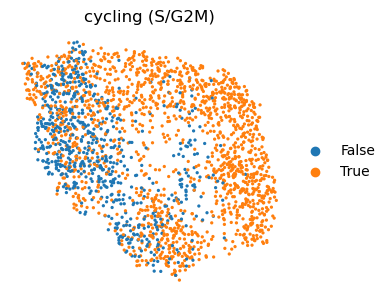

In [12]:
# diagnostic: cycling on the integrated manifold (no separate proliferation compartment)
fig, ax = plt.subplots(figsize=(3.6, 3.4))
sc.pl.umap(adata, color='cycling', size=22, ax=ax, show=False, frameon=False, title='cycling (S/G2M)')
plt.show()

## House linear orientation

The manifold is an elongated single strip. Rotate rigidly so the maximal-variance axis is horizontal and place the pSom-high / Crest-low **developmental origin** on the left (Crest is developmentally late). Stored as `X_umap_lin` and reused by every downstream panel for one consistent orientation.

In [13]:
xy = adata.obsm['X_umap']; c0 = xy - xy.mean(0)
aspect = c0.std(0).max()/c0.std(0).min()
_,_,vt = np.linalg.svd(c0, full_matrices=False)
th_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-th_rot),-np.sin(-th_rot)],[np.sin(-th_rot),np.cos(-th_rot)]])
xyr = c0 @ Rm.T
origin = adata.obs['pSom_sm'].values - adata.obs['Crest_sm'].values  # pSom-high / Crest-low origin pole
w = origin - origin.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(th_rot):+.1f}deg (distances preserved); pSom-high/Crest-low origin on left; stored X_umap_lin')

manifold aspect (max/min std): 2.11
house orientation: rigid rotation -10.5deg (distances preserved); pSom-high/Crest-low origin on left; stored X_umap_lin


## Gate 1 — mixing + continuity (iLISI)

iLISI (effective #samples among 90 neighbours) measures per-neighbourhood intermixing; combined with the single-component continuity check this judges Gate 1 on the regenerated embedding, not a scalar alone.

Continuity is judged **off an independent representation**: connected components of the Harmony-PCA kNN graph (built on `X_pca_harmony`), not the `X_umap` coordinates being visually inspected — the island-removal step above is only a display-space cleanup.

In [14]:
def _ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
n_samp = adata.obs['sample'].nunique()
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values))
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta=10) {il_post:.2f} of {n_samp} samples')
print(f'{n_samp} samples share one continuous manifold ({N_REMOVED} islands removed).')
from scipy.sparse.csgraph import connected_components as _cc
n_comp_ind, _ = _cc(adata.obsp['connectivities'], directed=False)
print(f'independent continuity: PCA-harmony kNN graph = {n_comp_ind} connected component(s) '
      '(checked off X_pca_harmony, NOT the UMAP being visually judged)')
print('GATE 1: samples intermix per-neighbourhood (iLISI %.2f/%d) on one continuous manifold (independent PCA-harmony graph: %d component) -> GO' % (il_post, n_samp, n_comp_ind))

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=10) 3.89 of 9 samples
9 samples share one continuous manifold (0 islands removed).
independent continuity: PCA-harmony kNN graph = 1 connected component(s) (checked off X_pca_harmony, NOT the UMAP being visually judged)
GATE 1: samples intermix per-neighbourhood (iLISI 3.89/9) on one continuous manifold (independent PCA-harmony graph: 1 component) -> GO


## Save processed.h5ad

In [15]:
protect = {'sample','celltype','cell_type','phase','patient','time_point','treatment','histology','tnm_stage','cell_subtype','mp_assignment','mp_top'}
for cc in list(adata.obs.columns):
    if cc in protect:
        adata.obs[cc] = adata.obs[cc].astype(str).astype('category'); continue
    col = adata.obs[cc]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        adata.obs[cc] = conv if (col.notna().sum()>0 and conv.notna().sum()>=0.9*col.notna().sum()) else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)
print(f'PROVENANCE malignant_raw={MAL_RAW} after_threshold={CELLS_AFTER_THRESH} after_island={CELLS_AFTER_ISLAND} n_hvg={N_HVG}')

saved processed.h5ad (2263, 12470)
PROVENANCE malignant_raw=2375 after_threshold=2263 after_island=2263 n_hvg=536


## samples.pdf — sample-coloured manifold (Gate-1 deliverable)

House style `(3.5,1.5)` horizontal strip on the linear orientation; sample intermixing across the strip is the batch-integration evidence.

saved samples.pdf | cells: 2263


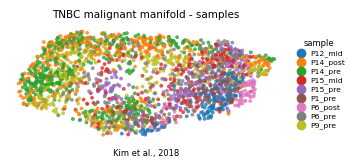

In [16]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('TNBC malignant manifold - samples', size=7.5)
ax.text(.5,-.12,'Kim et al., 2018', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight'); plt.show()
print('saved samples.pdf | cells:', plot.shape[0])